# Portable x-ray transport in Medicare, 2024: three measurements from public billing data

When Medicare pays for an x-ray taken at a patient's bedside (in a nursing home, an assisted-living facility or a private home), the supplier also bills for bringing the equipment there. The code descriptors bill transport *per trip to a facility or location*, using one of two codes:

| code | meaning |
|---|---|
| **R0070** | a trip to a location where **one** patient is seen |
| **R0075** | a trip to a location where **more than one** patient is seen (billed once per patient) |

A van can chain several such trips in a day. The data count patients per stop, not van runs. This notebook answers three questions with these codes:

1. **Solo stops.** How many visits are a stop with a single patient?
2. **Stop size.** When a stop is shared, how many patients does it serve? The file does not say directly; the payment rule lets us derive it.
3. **Concentration.** How concentrated is the billing across suppliers?

Every number below is computed from the public file in this repository. The checks in the **Controls** section run before any finding is computed.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from cms_transport.fetch import load_snapshot, DATASET_ID
from cms_transport import analysis as A, charts

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG = ROOT / "figures"
df = load_snapshot()
df.head()

,biller,entity_code,provider_type,hcpcs,setting,beneficiaries,services,beneficiary_days,avg_allowed
0,B001,O,Portable X-Ray Supplier,Q0092,O,15737,31832,26934,23.238
1,B002,O,Portable X-Ray Supplier,Q0092,F,417,681,681,27.698
2,B002,O,Portable X-Ray Supplier,Q0092,O,61,74,74,27.689
3,B003,O,Portable X-Ray Supplier,Q0092,O,1694,2773,2351,24.430
4,B004,O,Portable X-Ray Supplier,Q0092,O,1485,2913,2293,23.945


## The data

* **Source.** *Medicare Physician & Other Practitioners: by Provider and Service*, calendar year 2024, published by CMS on data.cms.gov. There is one row per rendering NPI, HCPCS code and setting.
* **Rows used.** R0070, R0075 and the set-up code Q0092, which serves only as a control. The pull has 875 rows.
* **Grain.** A *line* is one billed service (`Tot_Srvcs`). Transport is billed once per patient per day, so a line is one patient visit. A *biller* is one rendering NPI. The setting is `F` (facility) or `O` (non-facility: homes, assisted living and nursing facilities all fall here).
* **What is not in this repository.** Names and addresses were never written to disk. NPIs are replaced by pseudonyms (`B001`…), so no table or chart can single out a company. `python -m cms_transport.fetch --check` re-pulls the file from the CMS API and confirms the snapshot is identical.

In [2]:
print("dataset:", DATASET_ID)
print(df.groupby("hcpcs").agg(rows=("biller", "size"), billers=("biller", "nunique"), lines=("services", "sum")))
print()
print(df[df.hcpcs.isin(A.TRANSPORT)].groupby("provider_type").biller.nunique().rename("billers"))

dataset: 92396110-2aed-4d63-a6a2-5d6207d46a29
       rows  billers    lines
hcpcs                        
Q0092   331      287  1305363
R0070   327      286   723699
R0075   217      196   385487

provider_type
Independent Diagnostic Testing Facility (IDTF)      3
Portable X-Ray Supplier                           284
Name: billers, dtype: int64


## Controls

Each control can fail. If CMS revises the file, or the pull drops rows, these checks say so before any finding is computed.

* The first three confirm that this is the same file pulled on 15 September 2026: the row count, the line total, and a known row.
* The suppression floor is what makes the smallest billers invisible, so it is tested rather than assumed.
* Lines per beneficiary-day near 1.00 confirms that a transport line is one patient on one day. Analysis 1 rests on that.

In [3]:
checks = A.controls(df)
table = pd.DataFrame([vars(c) for c in checks])
assert table.passed.all(), table[~table.passed]
table

,name,expected,measured,passed
0,rows in the pull,875,875,True
1,transport + set-up lines,"2,414,549","2,414,549",True
2,a known row from the first pull is present (R0...,found,found,True
3,smallest beneficiary count in any row (CMS sup...,11,11,True
4,R0070 lines per beneficiary-day (one transport...,≈ 1.00,1.001,True
5,R0075 lines per beneficiary-day,≈ 1.00,1.001,True
6,billers on a transport code = union of the two...,287,287,True


## Finding 1: two in three visits, and about five in six stops, have a single patient

**Method.** An R0070 line is a solo stop: one line, one visit, one trip to a location. R0075 lines are visits at a shared stop. The solo share of **visits** is R0070 ÷ (R0070 + R0075), computed nationally and by setting. Turning visits into **stops** needs the number of patients per shared stop, which Finding 2 supplies.

In [4]:
s = A.solo_share(df)
print(f"solo-trip lines (R0070):    {s['solo_lines']:>9,}")
print(f"shared-stop lines (R0075):  {s['shared_lines']:>9,}")
print(f"solo share of visits:       {s['solo_share']:.1%}")
for k, v in s["by_setting"].items():
    print(f"  setting {k}: solo share {v['solo_share']:.1%}, {v['share_of_all_lines']:.1%} of all lines")
print(f"biller-setting pairs: {s['pairs_with_both']} bill both codes, {s['pairs_solo_only']} solo only, {s['pairs_shared_only']} shared only")
print(f"median pair's solo share, pairs billing both codes: {s['pair_solo_share_median']:.1%} "
      f"(quartiles {s['pair_solo_share_q1']:.1%}–{s['pair_solo_share_q3']:.1%})")
print(f"median BILLER's solo share, all {s['billers']} billers, every setting: {s['biller_solo_share_median']:.1%} "
      f"(lower quartile {s['biller_solo_share_q1']:.1%}); {s['billers_no_shared_line']} billers have no shared-stop line at all")
by_size = A.solo_share_by_size(df)
print()
print("solo share of visits by biller decile (1 = largest tenth by transport lines):")
print(by_size.to_string(index=False, formatters={"solo_share": "{:.1%}".format}))
# Controls: the settings sum to the national totals, and the deciles hold every line.
assert sum(v["solo"] for v in s["by_setting"].values()) == s["solo_lines"]
assert sum(v["shared"] for v in s["by_setting"].values()) == s["shared_lines"]
assert by_size.billers.sum() == s["billers"]

solo-trip lines (R0070):      723,699
shared-stop lines (R0075):    385,487
solo share of visits:       65.2%
  setting O: solo share 65.3%, 97.6% of all lines
  setting F: solo share 63.8%, 2.4% of all lines
biller-setting pairs: 216 bill both codes, 111 solo only, 1 shared only
median pair's solo share, pairs billing both codes: 70.2% (quartiles 58.0%–82.1%)
median BILLER's solo share, all 287 billers, every setting: 82.2% (lower quartile 65.1%); 91 billers have no shared-stop line at all

solo share of visits by biller decile (1 = largest tenth by transport lines):
 decile  billers solo_share
      1       29      58.5%
      2       29      71.9%
      3       29      76.0%
      4       29      75.5%
      5       29      84.8%
      6       29      83.1%
      7       29      83.3%
      8       29      85.2%
      9       29      87.8%
     10       26      85.9%


The national 65% is pulled down by the largest billers.

- **By size.** The largest tenth of billers bill 58.5% of their visits as solo stops; every other decile is above 70%.
- **The median biller.** Counted over all 287 billers, the median is at 82% solo. 91 billers show no shared-stop line at all: they either run none, or run fewer than 11 beneficiaries' worth, which CMS suppresses.
- **The 70% figure.** That is the median among the 216 biller-setting pairs that bill both codes. It leaves out the 111 pairs that bill only solo stops.

**Controls specific to this finding.** Asserted in the cell above: the two settings sum to the national totals exactly, and the deciles hold every biller.

solo share of STOPS (derived from Finding 2's 2.56 patients per shared stop): 82.8%


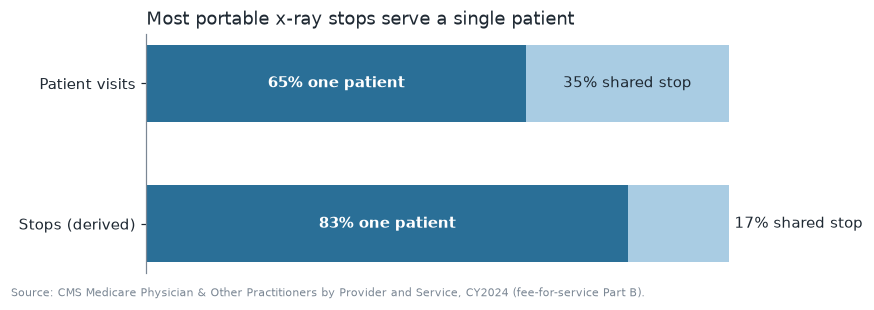

In [5]:
z = A.stop_sizes(df)
trip_share = A.solo_share_of_trips(df, z["weighted"])
print(f"solo share of STOPS (derived from Finding 2's {z['weighted']:.2f} patients per shared stop): {trip_share:.1%}")
charts.solo_vs_shared(s["solo_lines"], s["shared_lines"], trip_share, FIG / "1-solo-vs-shared.png");

**Limitations.**
* Medicare fee-for-service Part B only. Medicare Advantage, Medicaid and commercial visits are absent, and their mix is unknown.
* CMS suppresses any biller-code-setting cell with fewer than 11 beneficiaries, so the smallest billers are missing. Among visible billers, smaller ones bill a larger share of solo stops (the decile table). The true solo share is therefore probably somewhat above 65%.
* A patient in a Medicare Part A nursing-home stay has transport bundled into the facility's payment and never appears here.
* The setting flag cannot separate a private home from a nursing facility; both are non-facility.
* A stop is a trip to one location. A van run that chains several single-patient locations appears as several solo stops. The data cannot see runs.
* The stop figure is a derivation that rests on Finding 2. The visit figure is a direct count.

## Finding 2: a shared stop averages about 2.6 patients, not the six the rule allows

**Method.** Medicare's proration rule (Claims Processing Manual, Pub. 100-04, ch. 13, §90.3.4) pays each R0075 line the single-trip fee *divided by the number of patients at the stop*, with the divisor capped at six.

Take one biller in one setting. Let *F* be its R0070 allowed amount, and suppose its *T* shared-stop lines come from *S* stops, where the stop behind line *i* has *nᵢ* patients. Then:

$$\overline{R0075} = \frac{1}{T}\sum_i \frac{F}{n_i} = \frac{F \cdot S}{T} \quad\Rightarrow\quad \frac{F}{\overline{R0075}} = \frac{T}{S}$$

The *n* lines of one stop each contribute 1/*n*, so the sum is the number of stops, *S*. The ratio of the two published averages is therefore the mean number of patients per shared stop. Both amounts come from the same biller in the same setting, so its local fee schedule cancels within the pair and no fee table is needed.

**When it is exact.** Three conditions must hold:

1. Every stop has six patients or fewer. Larger stops price as six, so the estimate is then a floor.
2. Both codes are priced on the same fee basis.
3. Every patient counted in the divisor is in this file.

If the divisor counts patients of every payer, condition 3 fails. The ratio is then the harmonic mean of the *total* stop size, weighted by Medicare lines, rather than the mean number of Medicare patients per stop. Which reading applies depends on how suppliers count patients for the modifiers. That was not verified here.

**Check the algebra on synthetic stops before trusting it on real ones.** The cell below builds a biller with known stops, prices every line by the rule, and recovers the stop size from the two averages alone.

In [6]:
F = 100.0
stops = [2, 2, 3, 2, 4, 3, 2, 5]             # patients at each shared stop
priced = [F / min(n, 6) for n in stops for _ in range(n)]   # one line per patient
avg75 = sum(priced) / len(priced)
true_mean = sum(stops) / len(stops)
print(f"true mean stop size {true_mean:.4f}; recovered from averages {A.implied_stop_size(F, avg75):.4f}")
assert abs(A.implied_stop_size(F, avg75) - true_mean) < 1e-9

true mean stop size 2.8750; recovered from averages 2.8750


**Bounds.** The rule forces the ratio of the two averages into [1/6, 1/2]. A pair outside that band cannot have been priced by the rule, so it is excluded and counted rather than silently kept.

In [7]:
print(f"pairs with both codes {z['n_pairs']}; inside the band {z['n_used']}; excluded {z['n_pairs'] - z['n_used']} (ratios {z['excluded_ratios']})")
print(f"median {z['median']:.2f}, quartiles {z['q1']:.2f}–{z['q3']:.2f}, range {z['min']:.2f}–{z['max']:.2f}")
print(f"weighted by shared-stop visits: {z['weighted']:.2f}  (covers {z['covered_share']:.2%} of R0075 lines)")
for k, v in z["by_setting"].items():
    print(f"  setting {k}: {v['pairs']} pairs, median {v['median']:.2f}, weighted {v['weighted']:.2f}")
print(f"pairs whose average is at or near the six-patient cap (≥ 5.5): {z['at_floor']}")
# Controls: every pair is either used or excluded, and the used pairs cover the shared-stop lines.
assert z["n_used"] + len(z["excluded_ratios"]) == z["n_pairs"]
assert abs(z["bands"].share_of_shared_lines.sum() - 1) < 1e-12
z["bands"].style.format({"share_of_shared_lines": "{:.1%}"})

pairs with both codes 216; inside the band 214; excluded 2 (ratios [0.528, 0.549])
median 2.37, quartiles 2.24–2.52, range 1.96–5.68
weighted by shared-stop visits: 2.56  (covers 99.97% of R0075 lines)
  setting O: 189 pairs, median 2.36, weighted 2.56
  setting F: 25 pairs, median 2.46, weighted 2.48
pairs whose average is at or near the six-patient cap (≥ 5.5): 1


,band,pairs,share_of_shared_lines
0,1.9–2.5,152,35.6%
1,2.5–3.5,58,63.8%
2,3.5–4.5,2,0.2%
3,4.5–5.5,1,0.1%
4,5.5–7.0,1,0.3%


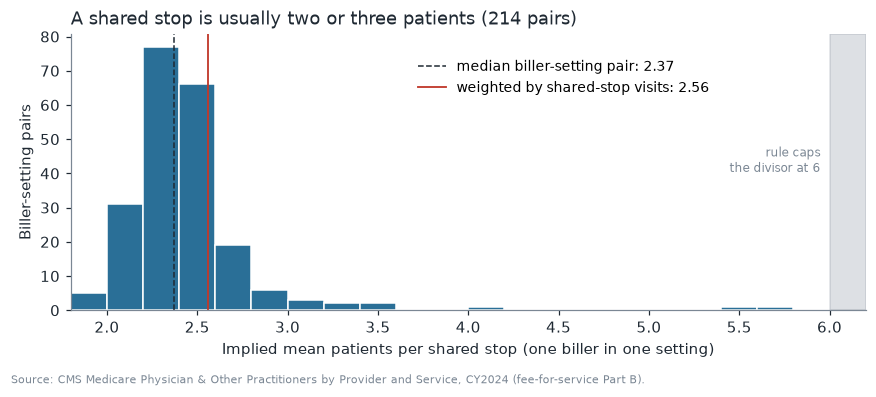

In [8]:
charts.stop_size_distribution(z["used"], z["median"], z["weighted"], FIG / "2-stop-size.png");

At the average shared stop the transport fee splits about 2.6 ways. The transport allowed amount behind each of those patients is therefore about 40% of a solo stop's.

**How the national figure is weighted.** The 2.56 pools allowed dollars: Σ F·T ÷ Σ F·S across pairs. Fees cancel within each pair, but the pooled figure is weighted by each pair's shared-stop lines *and* its fee level.

**Controls specific to this finding.** The synthetic check, and the band accounting asserted above.

- 214 of 216 pairs fall inside the band the rule allows.
- The two outside it (ratios 0.528 and 0.549) cannot have been priced by the rule as stated, so they are excluded.
- The smallest implied size inside the band, 1.96, is slightly below the 2.00 floor. Like the excluded pairs, it says this biller's two codes were not priced on exactly one basis. The band's tolerance admits it, and it is reported rather than hidden.

**Limitations.**
* This is a derivation from allowed amounts, not a count of stops. It holds where suppliers applied the patient-count modifiers the rule requires.
* Stops above six patients price as six, so very large rounds are understated. One pair's *average* sits at or near the cap. Large individual stops inside pairs with a low average cannot be seen.
* It is an average per biller. A biller that runs pairs one day and large rounds the next shows only the blend.
* The population limits of Finding 1 apply here too.

## Finding 3: the largest tenth of billers bill three-fifths of transport visits

**Method.** Sum R0070 and R0075 lines per biller, and allowed dollars as lines × average allowed amount. Rank billers by lines, then report the top ten, the top 25 and 50, deciles, the median and the small-biller tail. The single largest biller's share is not reported. A share of that size identifies a company as surely as its name, and for the same reason the top decile's upper bound is not printed.

In [9]:
c = A.concentration(df)
print(f"billers {c['billers']}; transport lines {c['lines']:,}; allowed dollars on the transport line ${c['dollars']/1e6:,.1f}M")
print(f"top 10 billers: {c['top10_lines']:.1%} of lines, {c['top10_dollars']:.1%} of dollars")
print(f"top 25: {c['top25_lines']:.1%} of lines; top 50: {c['top50_lines']:.1%}")
print(f"median biller: {c['median_lines']:,.0f} lines, ${c['median_dollars']:,.0f}; quartiles {c['q1_lines']:,.0f}–{c['q3_lines']:,.0f} lines")
print(f"billers under 1,000 lines: {c['under_1000']} of {c['billers']}, holding {c['under_1000_share_of_lines']:.1%} of lines")
print(f"billers over 10,000 lines: {c['over_10000']};  Gini of lines across visible billers: {c['gini']:.3f}")
d = c["deciles"].copy()
d["lines per biller"] = [f"{lo:,} and up" if i == 0 else f"{lo:,}–{hi:,}" for i, (lo, hi) in enumerate(zip(d.lines_low, d.lines_high))]
d.drop(columns=["lines_low", "lines_high"]).style.format({"share_of_lines": "{:.1%}", "share_of_dollars": "{:.1%}"}).hide(axis="index")

billers 287; transport lines 1,109,186; allowed dollars on the transport line $198.5M
top 10 billers: 40.5% of lines, 36.9% of dollars
top 25: 57.8% of lines; top 50: 74.0%
median biller: 977 lines, $204,340; quartiles 301–3,508 lines
billers under 1,000 lines: 146 of 287, holding 4.8% of lines
billers over 10,000 lines: 24;  Gini of lines across visible billers: 0.745


decile,billers,share_of_lines,share_of_dollars,lines per biller
1,29,61.2%,55.6%,"9,436 and up"
2,29,15.9%,18.3%,"4,043–8,880"
3,29,9.1%,10.4%,"2,971–3,995"
4,29,6.0%,6.6%,"1,728–2,912"
5,29,3.3%,3.8%,"953–1,673"
6,29,2.0%,2.4%,623–923
7,29,1.2%,1.5%,368–610
8,29,0.8%,0.9%,209–365
9,29,0.4%,0.4%,65–203
10,26,0.1%,0.1%,11–59


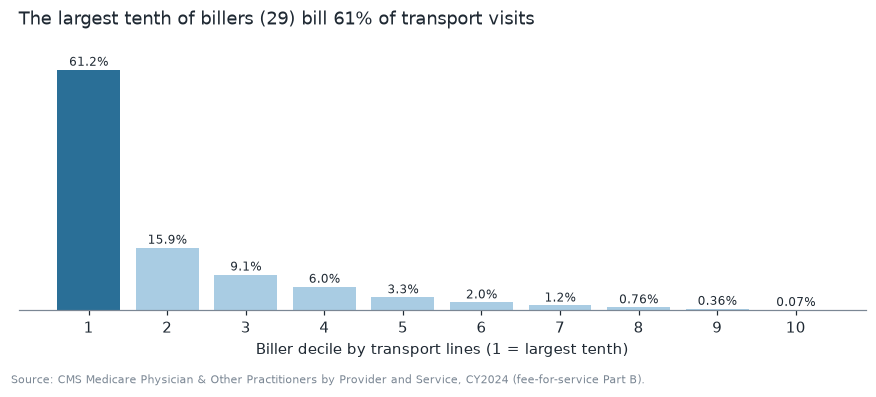

In [10]:
charts.concentration_deciles(c["deciles"], FIG / "3-concentration.png");

The top decile's dollar share (56%) is below its line share (61%). The largest billers run more shared stops (Finding 1), and a shared-stop line pays a fraction of a solo line (Finding 2).

**Controls specific to this finding.** The line total equals Finding 1's exactly. The biller count equals the union of both codes' billers. The decile shares sum to 100%.

In [11]:
assert c["lines"] == s["solo_lines"] + s["shared_lines"]
assert abs(c["deciles"].share_of_lines.sum() - 1) < 1e-12
print("concentration controls pass")

concentration controls pass


**Limitations.**
* A biller is a rendering NPI, and a company can bill under several. Concentration by company is therefore at least this high, and there are at most 287 companies.
* Suppression hides billers with fewer than 11 beneficiaries on a code in a setting, so the true tail of very small billers is longer than shown.
* Dollars are allowed amounts on the transport line only. They come before the exam fee, deductible, coinsurance and sequestration, so they are not revenue.
* Fee-for-service only. A biller's Medicare Advantage and commercial volume would change its rank.

## Reproducing this

```
pip install -r requirements.txt
python -m cms_transport.fetch --check      # optional: re-pull from data.cms.gov and compare
jupyter nbconvert --to notebook --execute --inplace notebooks/portable-xray-transport.ipynb
pytest
```